<a href="https://colab.research.google.com/github/tachom-a11/111111/blob/main/ipynb/ex_color_space_skin_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 肌領域の検出（Skin detection）
----

氏名：TIAN XINYE

学生番号：38926501

----
基本課題（必須）

    1. カラー画像にはどのような表現がありますか．各表現の利点・欠点を述べてください．



*   RGB（R:赤, G:緑, B:青）

    RGBの良いところは直感的なことで、人間の錐体細胞に対応しており、カメラの仕組みとも同じなので、写真の中の人物や背景を人間が直接識別しやすい。しかし、光などの外的要因の影響を受けやすく、同じ色でも明るさが違うとRGBの値が変わってしまうため、色に基づく特徴抽出には向かない。
*   HSV（H:色相, S:彩度, V:明度）

    HSVは人間が色を言葉で説明するときの感覚、すなわち何色か、どのくらい鮮やかか、どのくらい明るいかに近い。ただし、HSVの値はそのままでは正しい色で表示できないので、表示するときはRGBに戻す必要がある。明るさはVとして分離されており、Hは明るさの影響を比較的受けにくいため、Hから直接、対応する色の特徴を抽出できる。ただし、彩度の低い領域ではHが不安定になる。これは、HがRGBの三つの値の差によって決まるため、三つの値が近いときにノイズの影響を受けやすくなるからだと考えられる。

```
2. HSV空間にどのような条件を課すと肌領域を検出できますか．
    その条件はどのように見つけられますか．
```

  　HSVのHは色相を直接反映しており、また肌の色の色相は比較的狭い範囲、つまり赤からオレンジ付近に集中しているため、HSV空間のHに閾値を設定することで肌領域を検出できる。一般的には、3D scatter plotによって肌に近い色の点がどこに分布しているかを観察できる。ここで注意が必要なのは、plotを描くときに点の元の色も付けておく必要があることで、そうすることで必要な点の位置をより直感的に見つけられる。続いて、観察した分布をもとに大まかに閾値を設定し、この条件で抽出後の画像を生成する。それから、抽出結果と肌領域の正解マスクを比較し、両者の差を確認したうえで閾値を微調整する。

  　マスクの画像が手元にある場合は、より直接的に、マスクの中の黒以外の色のHSVヒストグラムを描いて分布を調べ、それによって肌の色のHが主にどの部分にあるかを確定し、Hに基づいて抽出用の大まかな閾値を設定できる。一般的には、分布の95%を含む範囲に設定すればよい。ただし、非常に暗い領域や明るい領域ではHが不安定になり、また肌の一部は白に近い色になるため、誤差を減らすために、マスクのHSVをもとにSとVの閾値も適切に設定し、ノイズを除外してもよい。



    3. 色だけを用いる肌領域の検出にはどのような問題点がありますか．また，どのような改善の工夫が考えられますか．

 　色だけで肌領域を検出するには限界があると考える。

 　今回の実験では、肌の色と黄色がよく似ているため、閾値をどれだけ狭く設定しても、背景の黄色や女の子が着ている黄色いスカートは常に肌として検出されてしまった。これは、閾値は色空間の中で直方体の形でしか領域を囲むことができないが、実際の肌の色の分布は不規則であるため、すべての肌の色を直方体で囲もうとすると、肌ではない色も多く含まれてしまうからである。参考文献でも、現実には家具や服など肌の色に似た物体が多いことが指摘されており、色だけで肌を検出すると誤検出が起こりやすい。

 　そして、HSVは光の明暗による色への影響をある程度弱めているが、各成分はやはり完全に独立しているわけではない。現実の環境は複雑で、物体は色の異なるさまざまな光に照らされ、さらに表面の反射やカメラの処理も加わることで、RGBの値が同じ比率で変化しなくなる。例えば顔の一部に強い光が当たると、これは顔のある部分に直接足し算をしたのと同じで、RGBにそれぞれほぼ同じ値が加わるが、比率は変わってしまうので、Vだけでなく、Sも下がり、Hもずれてしまう。このことから、明暗の変化はVだけに分離できないと分かる。それに、光自体に色がついている場合、例えば緑色の光が人に当たると、肌が反射できる赤い光が少なくなり、RGBの比率も同じように変わってしまう。そして、世界には人種がとても多く、肌の色の幅が非常に大きいので、すべての肌の色を含めるためにHの範囲をとても広く設定すると、実際には何も選別していないのと同じで、閾値を設定する意味もなくなってしまう。



    4.その他，気づいたこと，調べたことがあれば書いてください．

　RGBのヒストグラムを見ると、R、G、Bの三つの分布の形がほとんど同じで、どれも0に近い暗い部分でピークに達し、その後しばらく波打ってから一度下がり、明るい部分でまた少し上がって波打っている。ただし、谷の位置はRでは130付近、GとBでは200付近と、それぞれ違う。形が似ているのは、黒に近い色ではR、G、Bがすべて小さく、黒の部分が画像の中で比較的大きな領域を占めているためだと考えられる。白や灰色に近い色でもR、G、Bの値はほぼ同じになる。一方、それ以外の色ではR、G、Bの間の差が大きいので、三つのヒストグラムの谷はそれぞれ違う位置に現れる。参考文献でも、RGBの三つの成分は相関が非常に強く、どの成分にも色と明るさの情報が混ざっていると述べられている。このことから、RGBでは明暗と色を分けて扱うことができないと分かる。



----


In [1]:
#@title データセットをダウンロードします．
import zipfile
zipURL = "https://github.com/tsakailab/prml/raw/master/datasets/SkinDataset.zip"
!wget $zipURL --no-check-certificate --show-progress -q -O "/tmp/SkinDataset.zip"
with zipfile.ZipFile("/tmp/SkinDataset.zip", 'r') as f:
    f.extractall("./sample_data")


path_img = "./sample_data/SkinDataset/img"
path_lbl = "./sample_data/SkinDataset/lbl"
print("path_img = \"{}\"".format(path_img))
print("path_lbl = \"{}\"".format(path_lbl))

import os
imgfiles = [f for f in os.listdir(path_img) if os.path.isfile(os.path.join(path_img, f))]
print("imgfiles: list of filenames of " + str(len(imgfiles)) + " images in " + path_img)
lblfiles = [os.path.splitext(os.path.basename(f))[0]+".png" for f in imgfiles]
print("lblfiles: list of filenames of " + str(len(imgfiles)) + " skin masks in " + path_lbl)

import numpy as np
from PIL import Image
def read_images(filenames, path=path_img):
    imgs = []
    for f in filenames:
        img = Image.open(os.path.join(path, f))
        imgs.append(np.asarray(img))
    return imgs

/tmp/SkinDataset.zi 100%[===================>]   5.61M  --.-KB/s    in 0.06s   
path_img = "./sample_data/SkinDataset/img"
path_lbl = "./sample_data/SkinDataset/lbl"
imgfiles: list of filenames of 78 images in ./sample_data/SkinDataset/img
lblfiles: list of filenames of 78 skin masks in ./sample_data/SkinDataset/lbl


### `img_id` で指定した画像と正解の肌領域を表示し，画像のNumpy配列 `img` から画素値 [R, G, B] の3次元ベクトルの集まり `rgb` を作ります．

./sample_data/SkinDataset/img/2007_family.jpg


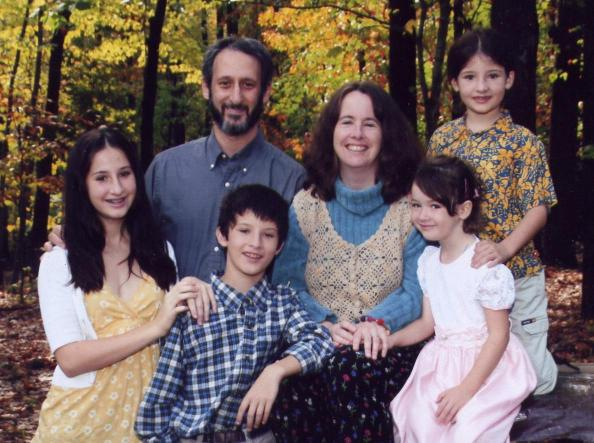

./sample_data/SkinDataset/lbl/2007_family.png


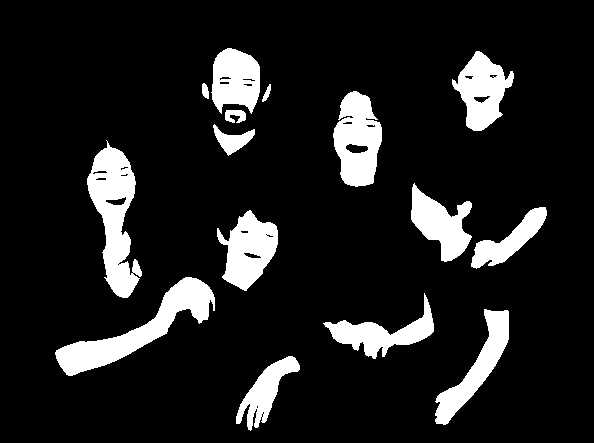

(443, 594, 3)


In [2]:
img_id = 1  # 0..77

import IPython.display as IPd
import os
im = IPd.Image(os.path.join(path_img, imgfiles[img_id]), width=300)
lb = IPd.Image(os.path.join(path_lbl, lblfiles[img_id]), width=300)
print(im.filename)
IPd.display(im)
print(lb.filename)
IPd.display(lb)

img = read_images([ imgfiles[img_id] ], path=path_img)[0]
lbl = read_images([ lblfiles[img_id] ], path=path_lbl)[0]
print(img.shape)

In [3]:
rgb = np.reshape(img, (-1,3))
print("rgb.shape =", rgb.shape)

import pandas as pd
print(pd.DataFrame(data=rgb, columns=["Red", "Green", "Blue"]).head(10))

rgb.shape = (263142, 3)
   Red  Green  Blue
0  196    200   105
1  170    174    77
2  156    156    60
3  152    150    50
4  152    147    47
5  168    159    56
6  192    180    78
7  204    191    87
8  195    178    74
9  178    161    57


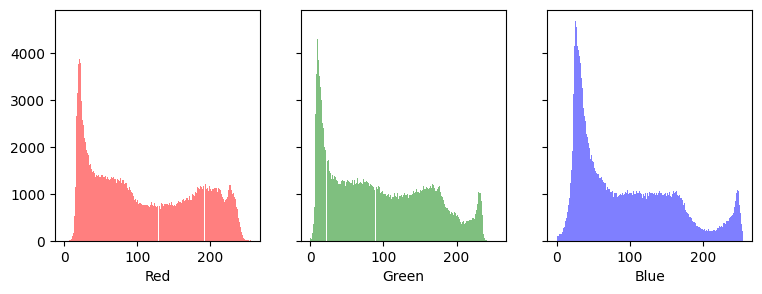

In [4]:
#@title 色のヒストグラムを表示します．
import matplotlib.pyplot as plt

fig, axes = plt.subplots(figsize=(9,3), nrows=1, ncols=3, sharex=True, sharey=True)
axes[0].hist(rgb[:,0], bins = 256, color = 'red', alpha = 0.5)
axes[0].set_xlabel('Red')
axes[1].hist(rgb[:,1], bins = 256, color = 'green', alpha = 0.5)
axes[1].set_xlabel('Green')
axes[2].hist(rgb[:,2], bins = 256, color = 'blue', alpha = 0.5)
axes[2].set_xlabel('Blue')
plt.show()

### RGB色空間で観察します．
- `ns`: 色空間に散布する画素数（画素全部は多すぎるので）．

In [5]:
ns = 3000

n = rgb.shape[0]
ns = min(n, ns)
print("Randomly chosen %d points out of %d points will be displayed." % (ns, n))

Randomly chosen 3000 points out of 263142 points will be displayed.


In [6]:
#@title RGB色空間を表示します．マウスで視点を操作して観察できます．
import plotly.graph_objs  as go
import plotly.graph_objs.layout  as gol

ps = np.random.choice(n, ns, replace=False)
rgbs = rgb[ps] # * 1.5 # brighter

# https://plotly.com/python-api-reference/generated/plotly.graph_objects.Scatter3d.html#plotly.graph_objects.Scatter3d
trace = go.Scatter3d(x=rgbs[:,0], y=rgbs[:,1], z=rgbs[:,2], mode='markers',
                     marker=dict(size=2,
                                color=['rgb({},{},{})'.format(r,g,b) for r,g,b in zip(rgbs[:,0], rgbs[:,1], rgbs[:,2])],
                                opacity=0.8))

layout = go.Layout(margin=dict(l=0,r=0,b=0,t=0), scene=gol.Scene(xaxis=gol.scene.XAxis(title="Red"), yaxis=gol.scene.YAxis(title="Green"), zaxis=gol.scene.ZAxis(title="Blue")))
fig = go.Figure(data=[trace], layout=layout)
camera = dict(up=dict(x=0, y=0, z=1), center=dict(x=0, y=0, z=0), eye=dict(x=1.5, y=1.5, z=0.8))
fig.update_layout(scene_camera=camera)
fig.show()

### ★ [HSV（Hue, Saturation, Value）](https://en.wikipedia.org/wiki/HSL_and_HSV)による表現に変換します．

In [7]:
import matplotlib.colors as colors
hsv = np.reshape(colors.rgb_to_hsv(img/255.0), (-1,3))
print(hsv.shape)

print("hsv.shape =", hsv.shape)

import pandas as pd
print(pd.DataFrame(data=hsv, columns=["Hue", "Saturation", "Value"]).head(10))

(263142, 3)
hsv.shape = (263142, 3)
        Hue  Saturation     Value
0  0.173684    0.475000  0.784314
1  0.173540    0.557471  0.682353
2  0.166667    0.615385  0.611765
3  0.163399    0.671053  0.596078
4  0.158730    0.690789  0.596078
5  0.153274    0.666667  0.658824
6  0.149123    0.593750  0.752941
7  0.148148    0.573529  0.800000
8  0.143251    0.620513  0.764706
9  0.143251    0.679775  0.698039


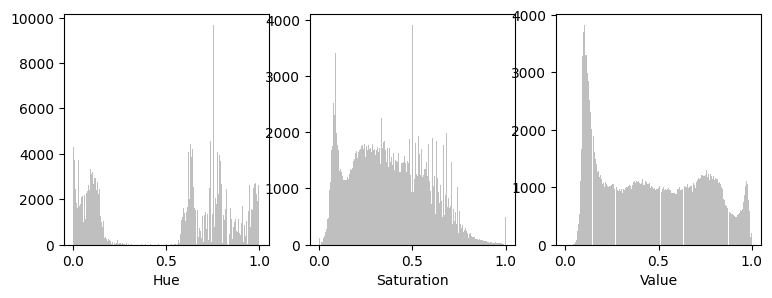

In [8]:
#@title HSVのヒストグラムを表示します．
import matplotlib.pyplot as plt

fig, axes = plt.subplots(figsize=(9,3), nrows=1, ncols=3, sharex=True, sharey=False)
axes[0].hist(hsv[:,0], bins = 256, color = 'gray', alpha = 0.5)
axes[0].set_xlabel('Hue')
axes[1].hist(hsv[:,1], bins = 256, color = 'gray', alpha = 0.5)
axes[1].set_xlabel('Saturation')
axes[2].hist(hsv[:,2], bins = 256, color = 'gray', alpha = 0.5)
axes[2].set_xlabel('Value')
plt.show()

In [9]:
#@title HSV色空間を観察します．マウスで視点を操作して観察できます．
import plotly.graph_objs  as go
import plotly.graph_objs.layout  as gol

nmax = 10000
def ScatterHSV(hsv, rgbs=None):
    if hsv.shape[0] > nmax:
        hsvs = hsv[np.random.choice(hsv.shape[0], nmax, replace=False),:]
    else:
        hsvs = hsv
    if rgbs is None: rgbs = colors.hsv_to_rgb(hsvs) * 255.

    # https://plotly.com/python-api-reference/generated/plotly.graph_objects.Scatter3d.html#plotly.graph_objects.Scatter3d
    trace = go.Scatter3d(x=hsvs[:,0], y=hsvs[:,1], z=hsvs[:,2], mode='markers',
                         marker=dict(size=2,
                                color=['rgb({},{},{})'.format(r,g,b) for r,g,b in zip(rgbs[:,0], rgbs[:,1], rgbs[:,2])],
                                opacity=0.8))
    layout = go.Layout(margin=dict(l=0,r=0,b=0,t=0),
                       scene=gol.Scene(
                           xaxis=gol.scene.XAxis(title="Hue", range=[0,1]),
                           yaxis=gol.scene.YAxis(title="Saturation", range=[0,1]),
                           zaxis=gol.scene.ZAxis(title="Value", range=[0,1])))
    fig = go.Figure(data=[trace], layout=layout)
    camera = dict(up=dict(x=0, y=0, z=1), center=dict(x=0, y=0, z=0), eye=dict(x=1, y=-2, z=0.8))
    fig.update_layout(scene_camera=camera)
    fig.show()

hsvs = hsv[ps]
ScatterHSV(hsvs)

78 / 78 images used, 3150484 skin pixels


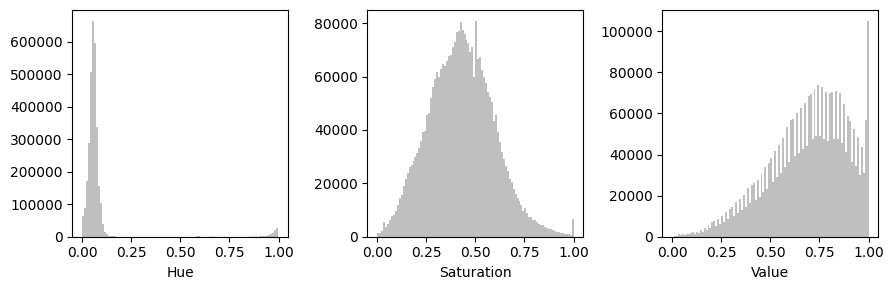

H: [0.02040816 0.10344828]
S: [0.16017316 0.70491803]
V: [0.32156863 0.98039216]


In [10]:
#@title  マスクのヒストグラムを表示します．
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import rgb_to_hsv

all_skin = []
for i in range(len(imgfiles)):
    im_i = read_images([imgfiles[i]], path=path_img)[0]
    lb_i = read_images([lblfiles[i]], path=path_lbl)[0]
    if lb_i.ndim == 3:
        lb_i = lb_i[:, :, 0]
    if lb_i.shape != im_i.shape[:2]:
        continue
    x = im_i / 255.0 if im_i.max() > 1 else im_i
    hsv_i = rgb_to_hsv(x).reshape(-1, 3)
    all_skin.append(hsv_i[(lb_i > lb_i.max() / 2).reshape(-1)])

hsv_skin_all = np.concatenate(all_skin)
print(len(all_skin), "/", len(imgfiles), "images used,", hsv_skin_all.shape[0], "skin pixels")

fig, axes = plt.subplots(figsize=(9,3), nrows=1, ncols=3, sharex=True, sharey=False)
for i, name in enumerate(['Hue', 'Saturation', 'Value']):
    axes[i].hist(hsv_skin_all[:, i], bins=100, color='gray', alpha=0.5)
    axes[i].set_xlabel(name)
plt.tight_layout()
plt.show()

h = hsv_skin_all[:, 0].copy()
print("H:", np.percentile(h, [5, 95]))
print("S:", np.percentile(hsv_skin_all[:, 1], [5, 95]))
print("V:", np.percentile(hsv_skin_all[:, 2], [5, 95]))

### HSV表現で肌の画素を選び出す方法を考えよう．
- NumPy配列 `hsv` （★のセルを参照）の行が画素に対応します．
- `hsv`の3つの列 Hue，Saturation，Value の値に条件を課してください．条件を満たす画素（`hsv`の行）の番号のNumPy配列を `skin_pos` とします．
    - 例えば，`hsv[:,2] > 0.2` と書くと，Value が 0.2を超える条件を表します．
- 条件を満たす画素の番号の配列は `skin_pos =`[`np.where(条件)[0]`](https://numpy.org/doc/stable/reference/generated/numpy.where.html)のように作成できます．
    - 行についての結果のみを使用するため末尾に`[0]`を付けています．
    - 複数の条件を課すときは，`skin_pos = np.where( logical_and([条件1,条件2,...,条件n]) )[0]`のように書きます．`logical_or`もあります．
    - [for文を書いたら負けかなと思ってる．](https://www.google.com/search?q=python+for+%E8%B2%A0%E3%81%91&rlz=1C1QABZ_jaJP862JP862&sxsrf=ALiCzsb_mbOOWtLLdk8-1feR5u76sZAMxw%3A1665660365256&ei=zfVHY4ioD-_s2roP8aqtiAY&ved=0ahUKEwjIwoyzjN36AhVvtlYBHXFVC2EQ4dUDCA4&uact=5&oq=python+for+%E8%B2%A0%E3%81%91&gs_lcp=Cgdnd3Mtd2l6EAMyBAgAEB46BwgAEB4QogQ6BQgAEKIEOgYIABAHEB5KBAhNGAFKBAhBGABKBAhGGABQAFidCmDADGgAcAF4AIABeYgBgAaSAQMxLjaYAQCgAQHAAQE&sclient=gws-wiz)

In [11]:
from functools import reduce
logical_and = lambda conds: reduce(np.logical_and, conds)
logical_or = lambda conds: reduce(np.logical_or, conds)

skin_pos = np.where(logical_or([
    logical_and([hsv[:,0] > 0.02040816, hsv[:,0] < 0.10344828,
                 hsv[:,1] > 0.20, hsv[:,1] < 0.50,
                 hsv[:,2] > 0.32, hsv[:,2] < 0.85]),
    logical_and([hsv[:,0] > 0.95,
                 hsv[:,1] > 0.12, hsv[:,1] < 0.45,
                 hsv[:,2] > 0.32, hsv[:,2] < 0.85]),
]))[0]


print(skin_pos.shape[0], "pixels are selected.")
ScatterHSV(hsv[skin_pos])

36206 pixels are selected.


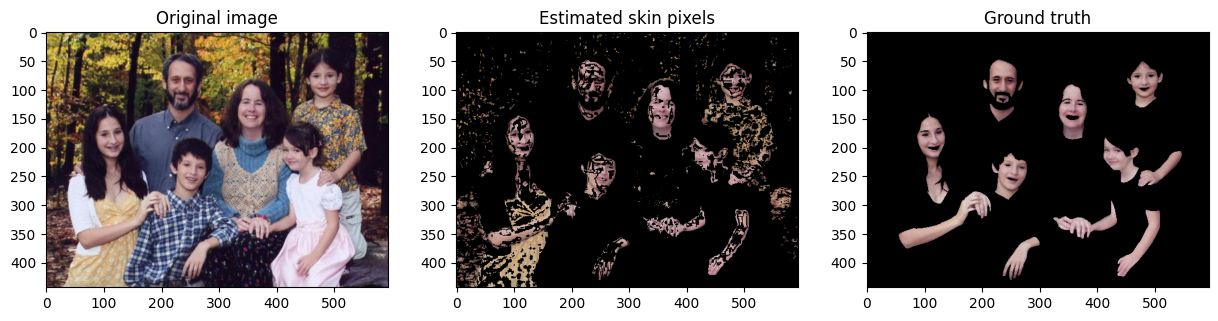

In [12]:
#@title 検出結果を画像で表示します．

#est = np.ones_like(rgb) * 255
est = np.zeros_like(rgb)

est[skin_pos,:] = rgb[skin_pos,:]
est = np.reshape(est, img.shape)

gt = np.zeros_like(img[:,:,:3])
idx_lbl = lbl[:,:,:3] > 0
gt[idx_lbl] = img[:,:,:3][idx_lbl]

plt.figure(figsize=(15,4))
plt.subplot(1,3,1)
plt.imshow(img)
plt.gca().set_title("Original image")
plt.subplot(1,3,2)
plt.imshow(est)
plt.gca().set_title("Estimated skin pixels")
plt.subplot(1,3,3)
plt.imshow(gt)
plt.gca().set_title("Ground truth")
plt.show()

In [13]:
#@title 混同行列（行：正解，列：予測）と評価値
from sklearn import metrics
# https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html

y_true = idx_lbl[:,:,0].ravel()
y_pred = np.full_like(y_true, False)
y_pred[skin_pos] = True
cm = metrics.confusion_matrix(y_true, y_pred)
print(cm)

print(metrics.classification_report(y_true, y_pred, labels=[True], target_names=["skin pixels"]))

[[212477  18599]
 [ 14459  17607]]
              precision    recall  f1-score   support

 skin pixels       0.49      0.55      0.52     32066

   micro avg       0.49      0.55      0.52     32066
   macro avg       0.49      0.55      0.52     32066
weighted avg       0.49      0.55      0.52     32066



--------

## 発展課題

畳み込みによる局所特徴の抽出に関する[こちらの教材](https://colab.research.google.com/github/tsakailab/alpp/blob/main/colab/alpp_local_operations.ipynb)に取り組んでください．


- 画像がもつ情報は，局所的な特徴（断片的な形状，模様，配色）の組合せによって表されています．**畳み込み（convolution）** は，画像の **局所特徴（local features）** の量を算出する基本的な演算です．
- カーネルを何種類も用意すれば，エッジや凹凸の断片，色の組合せなど，様々な局所特徴について特徴マップを作成できます．
- ３枚の入力で表せるカラー画像から特徴マップを出力するときと同様に，複数の特徴マップからひとつの特徴マップを作ることもできます．この特徴抽出は，畳み込みニューラルネットワーク（convolutional neural network）の原理となっています．

###CNNに基づく肌領域の検出

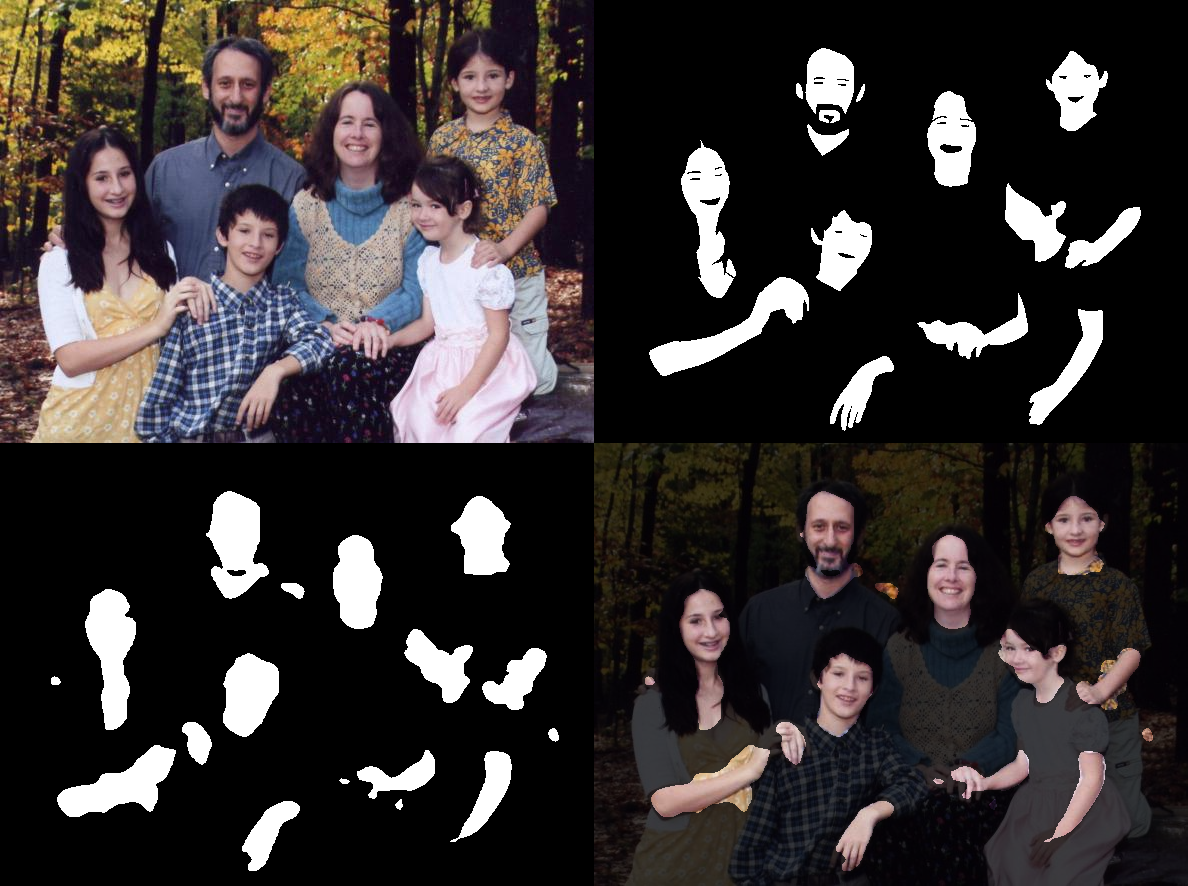

　CNNに基づく領域識別は、単に閾値の範囲を設定する方法よりも正確であることがわかる。CNNは多層の畳み込みを行うため、非線形の特徴を識別できる。畳み込みと活性化関数のうち、活性化関数は非線形であり、非線形の特徴を捉えることができる。

　これは、max poolingを行う際に、画像が縮小され続けるためだと考えられる。skip connectionによって一部の細部は復元できるが、特に細かい部分は復元できない。

## Next, try on a color image.<br>次は，カラー画像で試します．

In [14]:
uri = "https://raw.githubusercontent.com/tsakailab/alpp/refs/heads/main/data/330px-RYB_Color_wheel.png"
#uri = "https://raw.githubusercontent.com/tsakailab/alpp/refs/heads/main/data/peppers.png"
#uri = "https://otamatone.jp/cms/wp-content/uploads/2019/09/190421_otamatone71638-300x300.jpg"

/tmp/ipykernel_1143/2963892259.py:3: DeprecationWarning:

Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.



(height, width, channels) = (128, 171, 3)


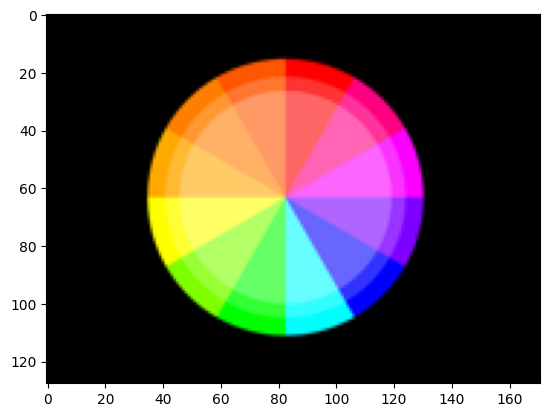

In [15]:
#@title Downloads and displays an image.<br>画像をダウンロードして表示します．
import imageio
cimg = imageio.imread(uri)

# resize
import numpy as np
from PIL import Image
cimg = np.array(Image.fromarray(cimg).resize((cimg.shape[1] * 128 // cimg.shape[0], 128)))

print("(height, width, channels) =", cimg.shape)
import matplotlib.pyplot as plt
plt.imshow(cimg)
plt.show()

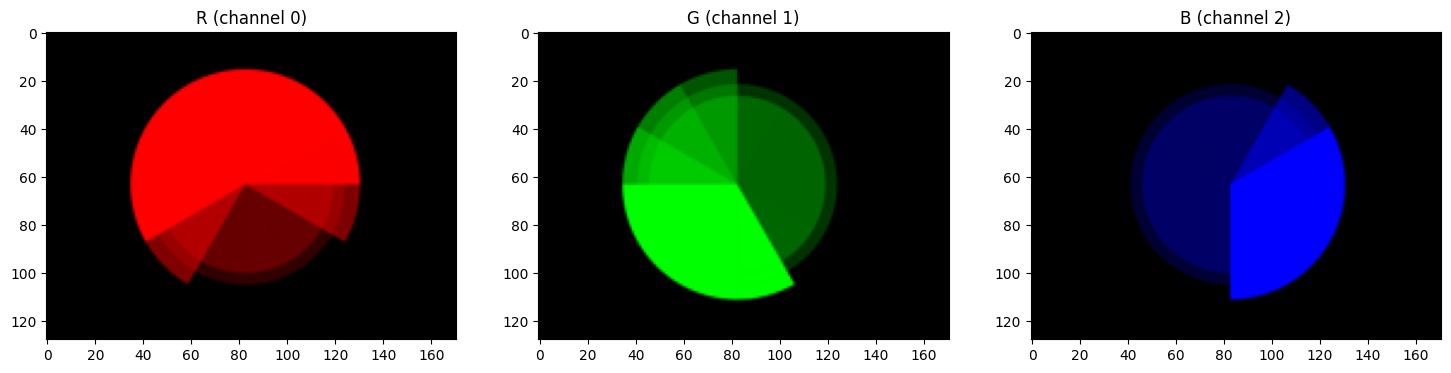

In [16]:
#@title A color image is represented as a collection of pixel values (R,G,B).<br>カラー画像は画素値 (R,G,B) の集まりで表されています．
import numpy as np
from matplotlib.colors import LinearSegmentedColormap as lsc

plt.figure(figsize=(18,6))

plt.subplot(1,3,1)
plt.title("R (channel 0)")
plt.imshow(cimg[:,:,0], cmap=lsc.from_list('kr', [(0,0,0), (1,0,0)], N=255))

plt.subplot(1,3,2)
plt.title("G (channel 1)")
plt.imshow(cimg[:,:,1], cmap=lsc.from_list('kg', [(0,0,0), (0,1,0)], N=255))

plt.subplot(1,3,3)
plt.title("B (channel 2)")
plt.imshow(cimg[:,:,2], cmap=lsc.from_list('kb', [(0,0,0), (0,0,1)], N=255))

plt.show()

In [17]:
kernel_ch0 = [[ 0, 0, 0],
              [  0,  1,  0],
              [  0,  0,  0]]

kernel_ch1 = [[  0,  0,  0],
              [  0,  1,  0],
              [  0,  0,  0]]

kernel_ch2 = [[  0,  0,  0],
              [  0,  1,  0],
              [  0,  0,  0]]

In [18]:
#@title PyTorchの畳み込み層にカーネルを設定します．
import torch
ker = torch.tensor([kernel_ch0, kernel_ch1, kernel_ch2]).unsqueeze(0)

#Conv2d(in_channels, out_channels, kernel_size, options)
conv = torch.nn.Conv2d(3, 1, 3, bias=False, padding=1)
conv.weight = torch.nn.Parameter(ker.float())
print("(out_channels, in_channels, kernel height, kernel width) =", conv.weight.shape)
print("\"conv\" made by torch.nn.Conv2d:", conv.weight)

(out_channels, in_channels, kernel height, kernel width) = torch.Size([1, 3, 3, 3])
"conv" made by torch.nn.Conv2d: Parameter containing:
tensor([[[[0., 0., 0.],
          [0., 1., 0.],
          [0., 0., 0.]],

         [[0., 0., 0.],
          [0., 1., 0.],
          [0., 0., 0.]],

         [[0., 0., 0.],
          [0., 1., 0.],
          [0., 0., 0.]]]], requires_grad=True)


Input:  <class 'torch.Tensor'> torch.Size([1, 3, 128, 171])
Output: <class 'torch.Tensor'> torch.Size([1, 1, 128, 171])


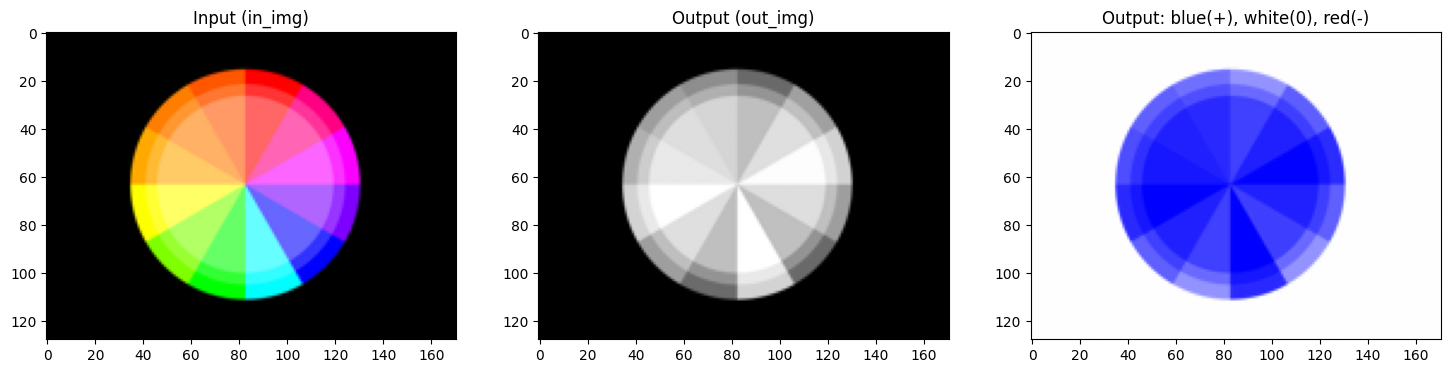

In [19]:
#@title Executes the convolution.<br>畳み込みを実行します．out_img = conv(in_img)
in_img = torch.tensor(cimg).permute(2,0,1).unsqueeze(0).float()
out_img = conv(in_img)

# (n, channels, height, width)
print("Input: ", type(in_img), in_img.shape)
print("Output:", type(out_img), out_img.shape)

plt.figure(figsize=(18,6))
plt.subplot(1,3,1)
plt.title("Input (in_img)")
plt.imshow(in_img[0].detach().permute(1,2,0).to(torch.int))

fmap = out_img[0,0].detach().numpy()
plt.subplot(1,3,2)
plt.title("Output (out_img)")
plt.imshow(fmap, cmap='gray')

from matplotlib.colors import TwoSlopeNorm as tsn
norm = tsn(vmin=np.minimum(fmap.min(),-1e-3), vcenter=0, vmax=np.maximum(fmap.max(),1e-3))
plt.subplot(1,3,3)
plt.title("Output: blue(+), white(0), red(-)")
plt.imshow(fmap, cmap='bwr_r', norm=norm)

plt.show()

###輝度を測る
kernel_ch0 = [[ 0, 0, 0],
              [  0,  1,  0],
              [  0,  0,  0]]

kernel_ch1 = [[  0,  0,  0],
              [  0,  1,  0],
              [  0,  0,  0]]

kernel_ch2 = [[  0,  0,  0],
              [  0,  1,  0],
              [  0,  0,  0]]
